# Hands-on: a Baltic SES digital twin in 60 minutes
### Fisheries + offshore wind + the public — the *Case-example II* model on real data

**SEAtwins Symposium training · SEADOTs (Horizon 101156488)**

We take the small social–ecological model from the Excel workbook (fish biomass *x*, windmills *w*, harvest *q*, investment *Iw*) and run it for a real case:

* **Fish stock:** Baltic sprat, *spr.27.22-32* — ICES 2025 assessment (SSB, catches, reference points)
* **Windmills:** the Polish offshore wind pipeline in the Baltic — national reporting (Aug 2026) and EMODnet Human Activities
* **Prices:** Polish sprat first-sale price (EUMOFA) and the Dec 2025 Polish offshore wind auction price

| Time | Part | You do |
|---|---|---|
| 0–5 min | 0. Setup | Run the first cells |
| 5–15 | 1. The Excel model in Python | Check that Python reproduces the Excel present value |
| 15–27 | 2. Real data | Load ICES and wind data (live, or the bundled snapshot) |
| 27–37 | 3. Calibration | Fit the fish growth function; set economic parameters |
| 37–50 | 4. Baltic scenarios | Run 4 scenarios; read stocks, benefits, Kobe, radar, present values |
| 50–60 | 5. Your turn | Change assumptions and see what changes the answer |

> **Honest labelling.** Each parameter below is tagged **DATA** (from a source), **FIT** (estimated here from data) or **ASSUMPTION** (a placeholder you are invited to change). The interaction and passive-use parameters are assumptions — no dataset gives them directly.

## 0. Setup (5 min)
Needs only `numpy`, `pandas`, `matplotlib` (and `requests` for the live data). Set `LIVE = False` if you have no internet — the bundled CSV snapshot in `data/` is used instead.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import json
from pathlib import Path

# Keep bundled snapshots beside the notebook so the exercise can run offline.

LIVE = True                     # try live ICES and EMODnet data; loaders fall back to bundled snapshots
DATA = Path("data")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
COL = {"S0": "#6b7280", "S1": "#2563eb", "S2": "#16a34a", "S3": "#d97706"}

## 1. The Excel model in Python (10 min)

These are the equations of the *Main* sheet of **Case-example II.xlsx**, unchanged. Time is in years, *t* = 0 … 25.

| | Equation (Excel) |
|---|---|
| Fish growth | $G(x,w) = (\alpha - \varepsilon_1 w)\,x - \beta x^2$ |
| Fish stock | $x_{t+1} = x_t + G(x_t,w_t) - q_t$ |
| Windmills | $w_{t+1} = w_t + I_{w,t} - \delta\, w_t$ |
| Fishery benefit | $b_f = p\,q - (c_1 + \varepsilon_2 w)\, q^{c_2} / x$ |
| Windmill benefit | $b_w = p_e\, w - c_{e1} w^{c_{e2}} - p_I\, I_w$ |
| Passive-use benefit | $b_p = u_1 (x+1)^{u_2} (w+1)^{u_3}$ |
| Present value | $PV = \sum_{t=0}^{25} (b_f+b_w+b_p)_t\,/\,(1+r)^{t+1}$ |

Two links make it a *system*: windmills change fish growth (ε₁) and fishing costs (ε₂), and both stocks enter the public's passive-use benefit.

*Feasible* harvest is capped at what is in the sea, $q_t \le x_t + G$ — as in the workbook.

### What the symbols mean

| Symbol | Meaning |
|---|---|
| $t$ | Year index, from 0 to 25; $t+1$ is the following year. |
| $x_t$ | Fish biomass (stock) at the start of year $t$. |
| $w_t$ | Installed offshore wind capacity at the start of year $t$. |
| $q_t$ | Fish harvested during year $t$. |
| $I_{w,t}$ | New wind capacity invested in during year $t$. |
| $G(x_t,w_t)$ | Natural fish-stock growth during year $t$, after accounting for the effect of wind capacity. |
| $\alpha,\beta$ | Fish-growth parameters: intrinsic growth and density dependence. |
| $\varepsilon_1$ | Effect of wind capacity on fish growth. |
| $\delta$ | Annual depreciation rate of installed wind capacity. |
| $b_f,b_w,b_p$ | Fishery, windmill, and passive-use benefits in a year. |
| $p$ | Revenue per unit of fish harvested. |
| $c_1,c_2$ | Fishery cost scale and catch-cost exponent. |
| $\varepsilon_2$ | Effect of wind capacity on fishing costs. |
| $p_e$ | Revenue per unit of installed wind capacity. |
| $c_{e1},c_{e2}$ | Wind operating-cost scale and capacity-cost exponent. |
| $p_I$ | Cost per unit of new wind investment. |
| $u_1,u_2,u_3$ | Scale and exponents for the modelled passive-use benefit from fish biomass and wind capacity. |
| $r$ | Annual discount rate used to convert future benefits to present value. |
| $PV$ | Sum of discounted annual benefits over the 26-year model period. |

All quantities use the model's units; the equations are unchanged from the workbook. The parameters are set in the following code cell.


In [ ]:
def simulate(P, harvest, invest, T=26, start_year=0):
    '''Run the Excel model.
    harvest: number, list of T numbers, or function f(t, x, w, P) -> attempted catch
    invest : list of T numbers (new capacity added in year t)'''
    # x and w are the current stocks; each loop records one year before advancing them.
    x, w, rows = P["x0"], P["w0"], []
    for t in range(T):
        # Logistic fish growth, reduced by wind capacity through eps1.
        G = (P["alpha"] - P["eps1"] * w) * x - P["beta"] * x**2
        # Accept a harvest rule, a year-by-year series, or one constant catch value.
        q_try = harvest(t, x, w, P) if callable(harvest) else (harvest[t] if np.ndim(harvest) else harvest)
        q = min(max(q_try, 0.0), max(x + G, 0.0))            # feasible harvest
        Iw = max(invest[t], -w)                               # feasible investment
        # Annual sector benefits correspond to b_f, b_w, and b_p in the equations above.
        bf = P["p"] * q - (P["cof1"] + P["eps2"] * w) * q**P["cof2"] / max(x, 1e-9)
        bw = P["pe"] * w - P["cofe1"] * w**P["cofe2"] - P["Iwp"] * Iw
        bp = P["pu1"] * (x + 1)**P["pu2"] * (w + 1)**P["pu3"]
        rows.append((start_year + t, x, w, q, Iw, bf, bw, bp))
        # Advance fish biomass after growth/catch and wind capacity after investment/depreciation.
        x, w = max(x + G - q, 0.0), w + Iw - P["dl"] * w
    d = pd.DataFrame(rows, columns=["year", "x", "w", "q", "Iw", "bf", "bw", "bp"])
    d["B"] = d.bf + d.bw + d.bp
    d["disc"] = (1 + P["roi"]) ** -(np.arange(T) + 1)           # Excel discounts year t by (1+r)^(t+1)
    return d

def present_values(d, P=None, terminal=False):
    '''PV by sector. terminal=True adds the depreciated replacement value of the wind fleet
    left in the last year (Iwp * w_T * (1-δ)), which the Excel workbook leaves out.'''
    # Discount each year's sector benefit and sum across the model horizon.
    pv = pd.Series({k: (d[k] * d.disc).sum() for k in ["bf", "bw", "bp", "B"]})
    if terminal:
        tv = P["Iwp"] * d.w.iloc[-1] * (1 - P["dl"]) * d.disc.iloc[-1]
        pv[["bw", "B"]] += tv
    return pv

**Check against the workbook.** Same parameters and controls as the *Main* sheet ($q$ = 0.354 each year; $I_w$ = 1.244 in year 0, then 0.012). The workbook shows **PV = 9.2208** (fishery 2.972, windmills 4.348, public 1.900).

In [ ]:
# Parameter-key translation: alpha/beta = α/β; cof* = c*; pe/cofe* = p_e/c_e*;
# Iwp/dl = p_I/δ; pu* = u*; eps* = ε*; roi = r; x0/w0 = initial stocks.
P_excel = dict(alpha=1, beta=0.5, p=1, cof1=0.4, cof2=1.1,           # fishery
               pe=0.5, cofe1=0.2, cofe2=1.5, Iwp=0.2, dl=0.01,        # windmills
               pu1=0.15, pu2=0.9, pu3=-1.1,                           # public
               eps1=0.1, eps2=0.1, x0=1, w0=0, roi=0.05)              # interactions, start, discount

# Compare the Python implementation with the workbook's example controls and PV.
d_excel = simulate(P_excel, harvest=0.354, invest=[1.244036] + [0.012122] * 25)
pv = present_values(d_excel)
print(pv.round(4).to_dict())
assert abs(pv.B - 9.2208246) < 1e-6, "does not match the Excel workbook"
print("✓ Python reproduces the Excel model exactly")

{'bf': 2.9724, 'bw': 4.3484, 'bp': 1.9, 'B': 9.2208}
✓ Python reproduces the Excel model exactly


## 2. Real data (12 min)

### 2a. Fish stock: Baltic sprat from the ICES Stock Assessment Graphs API
`spr.27.22-32`, assessment 2025 (key 20915). The API is public: `SummaryTable` gives the yearly SSB, catches and F, `FishStockReferencePoints` the reference points. If the call fails, the bundled snapshot (fetched from the same API on 26 Oct 2026) is used.

## Dataset guide: columns, sources, and model links

CSV snapshots are in `data/`; live loaders use the linked services and fall back to these snapshots. The equations use fish biomass and catch in **million tonnes (Mt)**, wind capacity and investment in **GW**, annual benefits in **EUR million**, and annual time steps.

| Dataset | Columns / content | Source and link to the equations |
|---|---|---|
| `ices_sprat_spr.27.22-32_2025_summary.csv` | `Year` (assessment year), `Recruitment` (number of fish), `Low_SSB`, `SSB`, `High_SSB` (tonnes; estimate and uncertainty bounds), `Catches`, `Landings` (tonnes), `F` (fishing mortality, ages 3–5). | ICES Stock Assessment Graphs API, [SummaryTable](https://sag.ices.dk/SAG_API/api/SummaryTable?assessmentKey=20915), stock `spr.27.22-32`, assessment 2025. `SSB / 1e6` becomes observed $x_t$ and is used to fit $\alpha,\beta$; `Catches / 1e6` becomes observed $q_t$ for calibration and context. `F` and uncertainty bounds are diagnostics, not direct equation terms. |
| `ices_sprat_spr.27.22-32_2025_refpoints.csv` | `StockKeyLabel`, `AssessmentKey`, `AssessmentYear`, `Blim`, `Bpa`, `MSYBtrigger` (biomass thresholds, tonnes), `FMSY`, `Fpa`, `FMGT_lower`, `FMGT_upper` (fishing-mortality reference rates). | Same [ICES assessment](https://sag.ices.dk/SAG_API/api/FishStockReferencePoints?assessmentKey=20915). Biomass thresholds are divided by `1e6` for model Mt and inform the harvest rule and plots; F reference rates are diagnostics. |
| `polish_offshore_wind_pipeline.csv` | `farm`, `developer`, `capacity_mw`, `status_aug2026`, `first_power_or_completion_year`, `source`. One row per project; some first-power years are stated assumptions where the source gives only a range. | National project compilation from [gramwzielone.pl, 26 Aug 2026](https://www.gramwzielone.pl/?p=20373718), with row-level provenance. Group capacity by first-power year and divide MW by 1,000 to get annual $I_{w,t}$; accumulated additions and depreciation determine $w_t$. Baltic West is excluded from contracted and included in full build-out. |
| `emodnet_windfarms_poland_2026-10-26.csv` | `name`, `status`, `power_mw`, `n_turbines`, `year`, `dist_coast_m`, `updateyear`, `lon`, `lat`. | [EMODnet Human Activities WFS](https://ows.emodnet-humanactivities.eu/wfs), layer `emodnet:windfarms`, country Poland. Coordinates and status/capacity are used in the location map; this point layer does not directly set $I_{w,t}$. |
| `economic_inputs.csv` | `parameter`, `value`, `unit`, `status`, `source`; one row per price, cost, or assumption. | Source is recorded per row. EUMOFA sprat price informs $p$; WindEurope auction price plus assumed capacity factor gives $p_e$; Baltica 2 investment/capacity gives $p_I$; lifetime gives $\delta$; `discount_rate` gives $r$; wind O&M gives $c_{e1}$, with $c_{e2}$ assumed linear. `fishing_cost_share` sets $c_1$ while $c_2$ is retained from Excel. The latest ICES SSB initializes $x_0$ and $w_0$ is set to zero. The interaction terms $\varepsilon_1,\varepsilon_2$ and passive-use parameters $u_1,u_2,u_3$ are assumptions without direct columns in these datasets. |
| `ne_10m_coastline_PL_Baltic.geojson` | GeoJSON `FeatureCollection` with coastline `MultiLineString` coordinate sequences, clipped to the Polish Baltic map extent (longitude/latitude). | [Natural Earth 1:10m coastline](https://github.com/nvkelso/natural-earth-vector/tree/master/geojson), public-domain map context for the EMODnet farm coordinates; not used in equations. |

The optional spatial-extension notebook also uses `era5_wind100m_hist_2020-2024.csv` (`kind`, site/cell `name`, farm/grid coordinates `lon`, `lat`, sampled `era5_lon`, `era5_lat`, `n_hours`, `mean_ws100`, and `hist_0_30`, a 31-bin hourly wind-speed histogram); `emodnet_natura2000_PL_marine_2026-10-26.geojson` (properties `sitecode`, `sitename`, `sitetype`, `sitedesc`, `area_ha`, `mar_perc`, plus polygon geometry); and `obis_sensitive_species_grid025_2026-10-26.csv` (`species`, cell `lon`/`lat`, `n_records`, `n_individuals`, `n_years`). These estimate site capacity factor and biodiversity sensitivity in the extension; they do not replace the main model's assumed $u_1,u_2,u_3$ or provide measured wind/fish interactions. Sources: [Open-Meteo historical weather API](https://open-meteo.com/en/docs/historical-weather-api), [EMODnet Human Activities](https://emodnet.ec.europa.eu/en/human-activities), and [OBIS](https://obis.org/).


In [ ]:
import requests
SAG = "https://sag.ices.dk/SAG_API/api"
KEY = 20915                                       # spr.27.22-32, assessment year 2025

def load_ices(live=LIVE):
    # SummaryTable supplies annual observations; the separate endpoint supplies reference points.
    if live:
        try:
            s = requests.get(f"{SAG}/SummaryTable", params={"assessmentKey": KEY}, timeout=20).json()
            r = requests.get(f"{SAG}/FishStockReferencePoints", params={"assessmentKey": KEY}, timeout=20).json()[0]
            ts = pd.DataFrame(s["Lines"])[["Year", "Recruitment", "Low_SSB", "SSB", "High_SSB", "Catches", "Landings", "F"]]
            ref = {k: float(r[k]) for k in ["Blim", "Bpa", "MSYBtrigger", "FMSY", "Fpa"]}
            print("ICES: live from the SAG API")
            return ts, ref
        except Exception as e:
            print("ICES live call failed -> bundled snapshot.", type(e).__name__, e)
    ts = pd.read_csv(DATA / "ices_sprat_spr.27.22-32_2025_summary.csv")
    r = pd.read_csv(DATA / "ices_sprat_spr.27.22-32_2025_refpoints.csv").iloc[0]
    ref = {k: float(r[k]) for k in ["Blim", "Bpa", "MSYBtrigger", "FMSY", "Fpa"]}
    print("ICES: bundled snapshot (26 Oct 2026)")
    return ts, ref

ices, ref = load_ices()
ices = ices.astype(float)
# ICES reports SSB and catch in tonnes; convert both to Mt for the model.
ices["x"] = ices.SSB / 1e6          # model units: million tonnes
ices["q"] = ices.Catches / 1e6
ref

ICES live call failed -> bundled snapshot. ProxyError HTTPSConnectionPool(host='sag.ices.dk', port=443): Max retries exceeded with url: /SAG_API/api/SummaryTable?assessmentKey=20915 (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))
ICES: bundled snapshot (26 Oct 2026)


{'Blim': 459000.0,
 'Bpa': 541000.0,
 'MSYBtrigger': 541000.0,
 'FMSY': 0.34,
 'Fpa': 0.35}

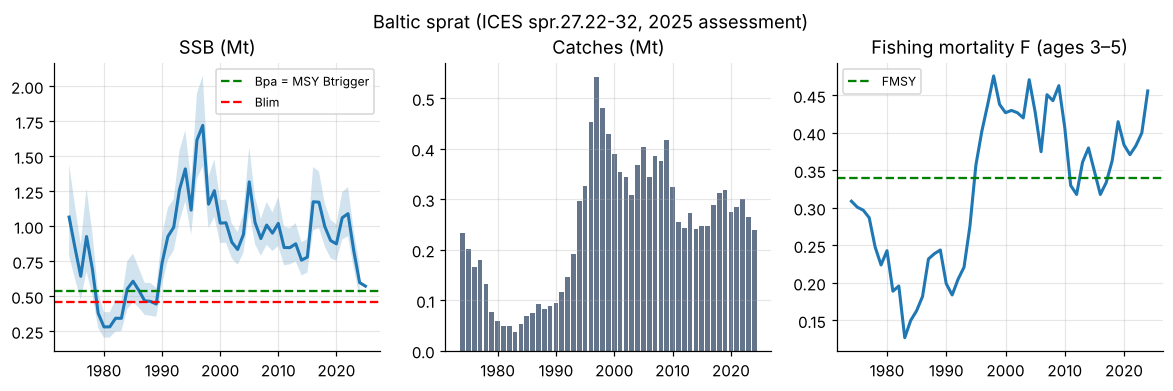

In [ ]:
# Plot observed stock, harvest, and fishing mortality against ICES reference points.
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].fill_between(ices.Year, ices.Low_SSB/1e6, ices.High_SSB/1e6, alpha=.2)
ax[0].plot(ices.Year, ices.x, lw=2); ax[0].set_title("SSB (Mt)")
ax[0].axhline(ref["Bpa"]/1e6, ls="--", c="g", label="Bpa = MSY Btrigger"); ax[0].axhline(ref["Blim"]/1e6, ls="--", c="r", label="Blim"); ax[0].legend(fontsize=8)
ax[1].bar(ices.Year, ices.q, color="#64748b"); ax[1].set_title("Catches (Mt)")
ax[2].plot(ices.Year, ices.F, lw=2); ax[2].axhline(ref["FMSY"], ls="--", c="g", label="FMSY"); ax[2].set_title("Fishing mortality F (ages 3–5)"); ax[2].legend(fontsize=8)
plt.suptitle("Baltic sprat (ICES spr.27.22-32, 2025 assessment)", y=1.02); plt.show()

### 2b. Windmills: the Polish offshore wind pipeline
Two sources, which do not fully agree — a typical data-integration situation:
* **National reporting** (gramwzielone.pl, 26 Aug 2026): projects under construction, auction winners and planned projects, with first-power years.
* **EMODnet Human Activities** WFS layer `emodnet:windfarms` (live, or snapshot of 26 Oct 2026). For Poland EMODnet holds **points only** (no farm polygons), and several statuses and years lag the national news.

In [ ]:
def load_emodnet_windfarms(live=LIVE):
    # Convert WFS point geometry into explicit lon/lat columns used by the map.
    if live:
        try:
            url = "https://ows.emodnet-humanactivities.eu/wfs"
            prm = {"service": "WFS", "version": "2.0.0", "request": "GetFeature", "typeNames": "emodnet:windfarms",
                   "outputFormat": "application/json", "srsName": "EPSG:4326", "CQL_FILTER": "country='Poland'"}
            fc = requests.get(url, params=prm, timeout=30).json()
            df = pd.DataFrame([{**f["properties"], "lon": f["geometry"]["coordinates"][0],
                                "lat": f["geometry"]["coordinates"][1]} for f in fc["features"]])
            print("EMODnet: live WFS,", len(df), "Polish wind farms")
            return df[["name", "status", "power_mw", "year", "lon", "lat"]]
        except Exception as e:
            print("EMODnet live call failed -> bundled snapshot.", type(e).__name__, e)
    df = pd.read_csv(DATA / "emodnet_windfarms_poland_2026-10-26.csv")
    print("EMODnet: bundled snapshot (26 Oct 2026),", len(df), "farms")
    return df[["name", "status", "power_mw", "year", "lon", "lat"]]

# EMODnet farm points support the location map; the national pipeline drives Iw,t below.
emod = load_emodnet_windfarms()
national = pd.read_csv(DATA / "polish_offshore_wind_pipeline.csv")
print(f"EMODnet total listed: {emod.power_mw.sum()/1000:.1f} GW  |  national pipeline: {national.capacity_mw.sum()/1000:.1f} GW")
national[["farm", "capacity_mw", "status_aug2026", "first_power_or_completion_year"]]

EMODnet live call failed -> bundled snapshot. ProxyError HTTPSConnectionPool(host='ows.emodnet-humanactivities.eu', port=443): Max retries exceeded with url: /wfs?service=WFS&version=2.0.0&request=GetFeature&typeNames=emodnet%3Awindfarms&outputFormat=application%2Fjson&srsName=EPSG%3A4326&CQL_FILTER=country%3D%27Poland%27 (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))
EMODnet: bundled snapshot (26 Oct 2026), 26 farms
EMODnet total listed: 20.9 GW  |  national pipeline: 13.4 GW


,farm,capacity_mw,status_aug2026,first_power_or_completion_year
0,MFW Baltic Power,1200,construction (first power 10 Jul 2026),2026
1,Baltica 2,1500,construction,2027
2,Baltyk 2 + Baltyk 3,1440,construction,2028
3,BC-Wind,390,construction,2028
4,Baltica 3,1000,planned,2030
5,MFW Baltyk 1,1560,planned (Dec 2025 auction),2032
6,Baltica 9+,1300,planned (Dec 2025 auction),2032
7,Baltic East,900,planned (Dec 2025 auction),2032
8,Baltic West,4100,planned (surveys),2035


In [ ]:
# Draw the bundled Natural Earth coastline first, then overlay EMODnet farm points.
fig, ax = plt.subplots(figsize=(7.5, 4))
coast = json.loads((DATA / "ne_10m_coastline_PL_Baltic.geojson").read_text())
for feature in coast["features"]:
    for segment in feature["geometry"]["coordinates"]:
        xy = np.asarray(segment)
        ax.plot(xy[:, 0], xy[:, 1], color="#64748b", lw=1.1, zorder=1)
ax.set_facecolor("#eaf4f8")
c = emod.status.map({"Construction": "#d97706", "Production": "#16a34a"}).fillna("#2563eb")
ax.scatter(emod.lon, emod.lat, s=emod.power_mw / 6, c=c, alpha=.6, edgecolor="k", lw=.4)
for _, r in emod[emod.power_mw >= 900].iterrows():
    ax.annotate(r["name"].replace(" Offshore wind farm 1", ""), (r.lon, r.lat), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
ax.set_xlim(13, 20.5); ax.set_ylim(53, 56.5)
ax.set_xlabel("lon °E"); ax.set_ylabel("lat °N"); ax.set_aspect("equal", adjustable="box")
ax.set_title("EMODnet wind farms, Poland (size = MW; orange = construction, blue = planned)"); plt.show()

### 2c. Prices and costs

In [ ]:
# Prices and explicitly labelled assumptions are stored in long form.
econ = pd.read_csv(DATA / "economic_inputs.csv").set_index("parameter")
econ

,value,unit,status,source
parameter,,,,
sprat_first_sale_price_PL_2024,0.40,EUR/kg,data,EUMOFA species profile European sprat (Poland ...
offshore_wind_auction_price_2025,115.00,EUR/MWh,data,WindEurope 19 Dec 2025 (winning bids ~113-117 ...
baltica2_investment,7110.00,EUR million,data,Notes from Poland 31 Jan 2025 (Baltica 2 ~1.5 GW)
baltica2_capacity,1500.00,MW,data,gramwzielone.pl 26 Aug 2026
capacity_factor,0.45,share,assumption,large 14-15 MW turbines in the Polish Baltic; ...
wind_opex,60.00,EUR million per GW per year,assumption,order of magnitude for offshore O&M (60 EUR/kW...
turbine_lifetime,30.00,years,assumption,del = 1/lifetime
fishing_cost_share,0.85,share of revenue at 2024 state,assumption,replace with STECF AER pelagic trawl segment
discount_rate,0.05,per year,assumption,as in Excel model (roi)


## 3. Calibration (10 min)

### 3a. Fit the fish growth function to ICES data (**FIT**)
Rearranging the stock equation gives the *observed surplus production*: $S_t = x_{t+1} - x_t + q_t$. The Excel growth function says $S_t = \alpha x_t - \beta x_t^2$ (with no windmills yet, $w=0$), so α and β follow from a least-squares regression without intercept.

Units: *x* and *q* in **million tonnes SSB / catch**.

alpha = 0.483/yr   beta = 0.211 per Mt·yr   R² = 0.09   (years 1974–2024)
=> carrying capacity K = 2.29 Mt,  B_MSY = 1.15 Mt,  MSY = 0.277 Mt/yr


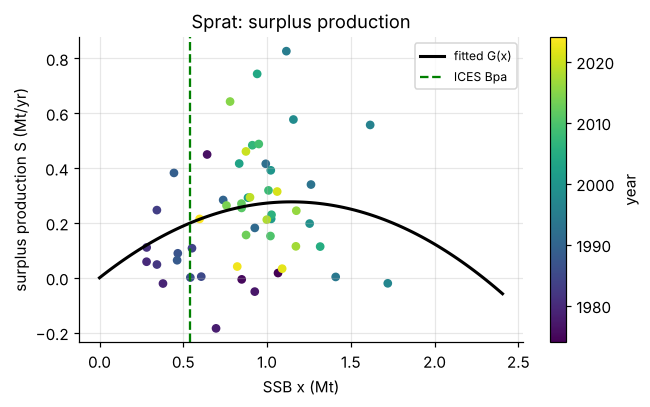

In [ ]:
FIT_FROM = 1974                                # try 1990 or 2000 in part 5

# Reconstruct annual surplus production from consecutive SSB values plus catch.
h = ices.dropna(subset=["x"]).reset_index(drop=True)
h["S"] = h.x.shift(-1) - h.x + h.q
fit = h[(h.Year >= FIT_FROM) & h.S.notna()]
# Fit S = alpha*x - beta*x**2 with no intercept, matching G(x, 0) in the model.
A = np.c_[fit.x, -fit.x**2]
(alpha, beta), *_ = np.linalg.lstsq(A, fit.S, rcond=None)
res = fit.S - A @ [alpha, beta]
R2 = 1 - (res**2).sum() / ((fit.S - fit.S.mean())**2).sum()
K, Bmsy, MSY = alpha / beta, alpha / (2 * beta), alpha**2 / (4 * beta)
print(f"alpha = {alpha:.3f}/yr   beta = {beta:.3f} per Mt·yr   R² = {R2:.2f}   (years {int(fit.Year.min())}–{int(fit.Year.max())})")
print(f"=> carrying capacity K = {K:.2f} Mt,  B_MSY = {Bmsy:.2f} Mt,  MSY = {MSY:.3f} Mt/yr")

xs = np.linspace(0, max(K, h.x.max()) * 1.05, 100)
plt.figure(figsize=(6.5, 3.6))
sc = plt.scatter(fit.x, fit.S, c=fit.Year, cmap="viridis", s=22); plt.colorbar(sc, label="year")
plt.plot(xs, alpha * xs - beta * xs**2, "k", lw=2, label="fitted G(x)")
plt.axvline(ref["Bpa"] / 1e6, ls="--", c="g", label="ICES Bpa")
plt.xlabel("SSB x (Mt)"); plt.ylabel("surplus production S (Mt/yr)"); plt.legend(fontsize=8); plt.title("Sprat: surplus production"); plt.show()

> **Discuss.** R² is low: sprat production is driven by recruitment and the environment (temperature, cod predation), not by SSB alone. This is exactly slide 20's warning — a simple *G(x)* is a strong simplification. It is still the best two-parameter description of the data, and it gives a *K* and *B*<sub>MSY</sub> of the right order.

### 3b. Economic parameters in real units
Money is in **EUR million per year**, windmill capacity *w* in **GW**, fish in **Mt**.

In [ ]:
# Translate source prices into model units and derive the remaining economic parameters.
x24, q24 = ices.loc[ices.Year == 2024, ["x", "q"]].iloc[0]
p_fish = econ.loc["sprat_first_sale_price_PL_2024", "value"] * 1000          # EUR/kg -> EUR m per Mt
cost_share = econ.loc["fishing_cost_share", "value"]
cof2 = 1.1                                                                   # Excel cost exponent kept
cof1 = cost_share * p_fish * q24 * x24 / q24**cof2                           # so costs = 85 % of revenue in 2024

cf = econ.loc["capacity_factor", "value"]
pe = econ.loc["offshore_wind_auction_price_2025", "value"] * 8760 * cf * 1000 / 1e6   # EUR m per GW per year
Iwp = econ.loc["baltica2_investment", "value"] / (econ.loc["baltica2_capacity", "value"] / 1000)  # EUR m per GW
dl = 1 / econ.loc["turbine_lifetime", "value"]

# Build P with workbook keys used by simulate(); comments tag data vs assumptions.
P = dict(
    alpha=alpha, beta=beta,                         # FIT  (ICES SSB + catches)
    p=p_fish,                                       # DATA (EUMOFA, PL 2024)
    cof1=cof1, cof2=cof2,                           # ASSUMPTION (85 % cost share; replace with STECF AER)
    pe=pe,                                          # DATA price (Dec 2025 auction) x ASSUMPTION capacity factor
    cofe1=econ.loc["wind_opex", "value"], cofe2=1.0,# ASSUMPTION O&M, linear (Excel used 1.5: try it in part 5)
    Iwp=Iwp,                                        # DATA (Baltica 2 investment / capacity)
    dl=dl,                                          # ASSUMPTION (30-year life)
    pu1=None, pu2=0.9, pu3=-0.05,                   # ASSUMPTION passive use (pu2 as in Excel)
    eps1=0.0, eps2=0.01 * cof1,                     # ASSUMPTION: no growth effect; +1 % fishing cost per GW
    x0=float(ices.loc[ices.Year == 2025, "x"].iloc[0]),   # DATA: SSB 2025
    w0=0.0,                                         # DATA: no Polish offshore capacity end 2025
    roi=econ.loc["discount_rate", "value"])
P["pu1"] = 100 / (Bmsy + 1) ** P["pu2"]             # ASSUMPTION: public values a stock at B_MSY at EUR 100 m/yr

pd.Series(P).to_frame("value")

,value
alpha,0.483
beta,0.211
p,400.000
cof1,234.273
cof2,1.100
pe,453.330
cofe1,60.000
cofe2,1.000
Iwp,4740.000
dl,0.033


Quick sanity check of what these numbers mean:

In [ ]:
print(f"Fishery revenue 2024  : {p_fish*q24:6.0f} EUR m   (catch {q24*1000:.0f} kt at {p_fish:.0f} EUR/t)")
print(f"Wind revenue per GW   : {pe:6.0f} EUR m/yr  (operating cost {P['cofe1']:.0f} EUR m/yr at 1 GW)")
print(f"Capital cost per GW   : {(P['roi']+dl)*Iwp:6.0f} EUR m/yr  (= (r + δ) × {Iwp:.0f} EUR m)")
print(f"PV of one GW's net revenue: {(pe-P['cofe1'])/(P['roi']+dl):6.0f} EUR m   vs investment {Iwp:.0f} EUR m")
print("-> at the auction price a GW of offshore wind roughly breaks even at 5 % — which is what a competitive CfD auction")
print("   should produce. So whether wind adds social value here depends on the interactions and on the public.")

Fishery revenue 2024  :     96 EUR m   (catch 240 kt at 400 EUR/t)
Wind revenue per GW   :    453 EUR m/yr  (operating cost 60 EUR m/yr at 1 GW)
Capital cost per GW   :    395 EUR m/yr  (= (r + δ) × 4740 EUR m)
PV of one GW's net revenue:   4720 EUR m   vs investment 4740 EUR m
-> at the auction price a GW of offshore wind roughly breaks even at 5 % — which is what a competitive CfD auction
   should produce. So whether wind adds social value here depends on the interactions and on the public.


### 3c. The investment path *I<sub>w</sub>(t)* from the national pipeline (**DATA**)
New capacity enters in its first-power/completion year; the year-*t* investment raises *w* from year *t*+1. Two variants: the **contracted** pipeline (construction + Dec 2025 auction winners + Baltica 3, 9.3 GW) and a **full** build-out adding Baltic West (4.1 GW, first power after 2034).

In [ ]:
YEARS = np.arange(2025, 2051)                                   # t = 0..25, as in the workbook
def invest_path(df):
    # Aggregate project MW by first-power year and convert annual additions to GW for Iw,t.
    g = df.groupby("first_power_or_completion_year").capacity_mw.sum() / 1000   # GW per year
    return [float(g.get(y, 0.0)) for y in YEARS]

Iw_contracted = invest_path(national[national.farm != "Baltic West"])
Iw_full       = invest_path(national)
pd.DataFrame({"contracted (GW)": Iw_contracted, "full (GW)": Iw_full}, index=YEARS).query("`full (GW)` > 0")

,contracted (GW),full (GW)
2026,1.20,1.20
2027,1.50,1.50
2028,1.83,1.83
2030,1.00,1.00
2032,3.76,3.76
2035,0.00,4.10


## 4. Baltic scenarios (13 min)

Controls are the two human actions of the model: the **catch** *q* and **wind investment** *I<sub>w</sub>*.

| | Catch rule | Wind | Interactions |
|---|---|---|---|
| **S0** | ICES-style rule: harvest rate *h*<sub>MSY</sub> = α/2, reduced linearly below MSY B<sub>trigger</sub> | none | — |
| **S1** | same rule | contracted 9.3 GW | base: +1 % fishing cost per GW, no growth effect |
| **S2** | same rule | full 13.4 GW | strong: windmills cut growth 5 % at full build-out, +5 % fishing cost per GW |
| **S3** | catch fixed at the 2024 level (240 kt), no rule | contracted 9.3 GW | base |

S0 → S1 isolates the effect of wind; S3 shows what happens without a harvest rule.

All present values include the **terminal value** of the wind fleet in 2050 (see part 5, exercise 5 for the Excel convention without it).

In [ ]:
# Scenario controls: fixed catch, or an ICES-style harvest rate reduced below Btrigger.
    return lambda t, x, w, P: level

def ices_rule(t, x, w, P):
    h_msy = (P["alpha"] - P["eps1"] * w) / 2                 # harvest rate at MSY for the logistic model
    return h_msy * min(1.0, x / (ref["MSYBtrigger"] / 1e6)) * x

# S2 uses stronger wind-fishery interactions; other scenarios retain the base assumptions.
S3_P = {**P, "eps1": 0.05 * P["alpha"] / sum(Iw_full), "eps2": 0.05 * P["cof1"]}
SCEN = {
    "S0": ("No wind, ICES rule",                 P,    ices_rule,        [0.0] * 26),
    "S1": ("Contracted wind, ICES rule",         P,    ices_rule,        Iw_contracted),
    "S2": ("Full wind, rule, strong links",      S3_P, ices_rule,        Iw_full),
    "S3": ("Contracted wind, fixed 2024 catch",  P,    fixed_catch(q24), Iw_contracted),
}
# Simulate each scenario with its parameters, harvest rule, and investment path.
runs = {k: simulate(Pk, hv, iw, start_year=2025) for k, (_, Pk, hv, iw) in SCEN.items()}
PV = pd.DataFrame({k: present_values(d, SCEN[k][1], terminal=True) for k, d in runs.items()}).T
PV.columns = ["Fishery", "Windmills", "Public", "Total"]
PV.index = [f"{k} {SCEN[k][0]}" for k in PV.index]
PV.round(0)

,Fishery,Windmills,Public,Total
"S0 No wind, ICES rule",629.0,0.0,1323.0,1952.0
"S1 Contracted wind, ICES rule",594.0,-118.0,1219.0,1695.0
"S2 Full wind, rule, strong links",371.0,-152.0,1198.0,1417.0
"S3 Contracted wind, fixed 2024 catch",-383.0,-118.0,775.0,274.0


### Evolution of the SES (stocks) and paths of human benefits

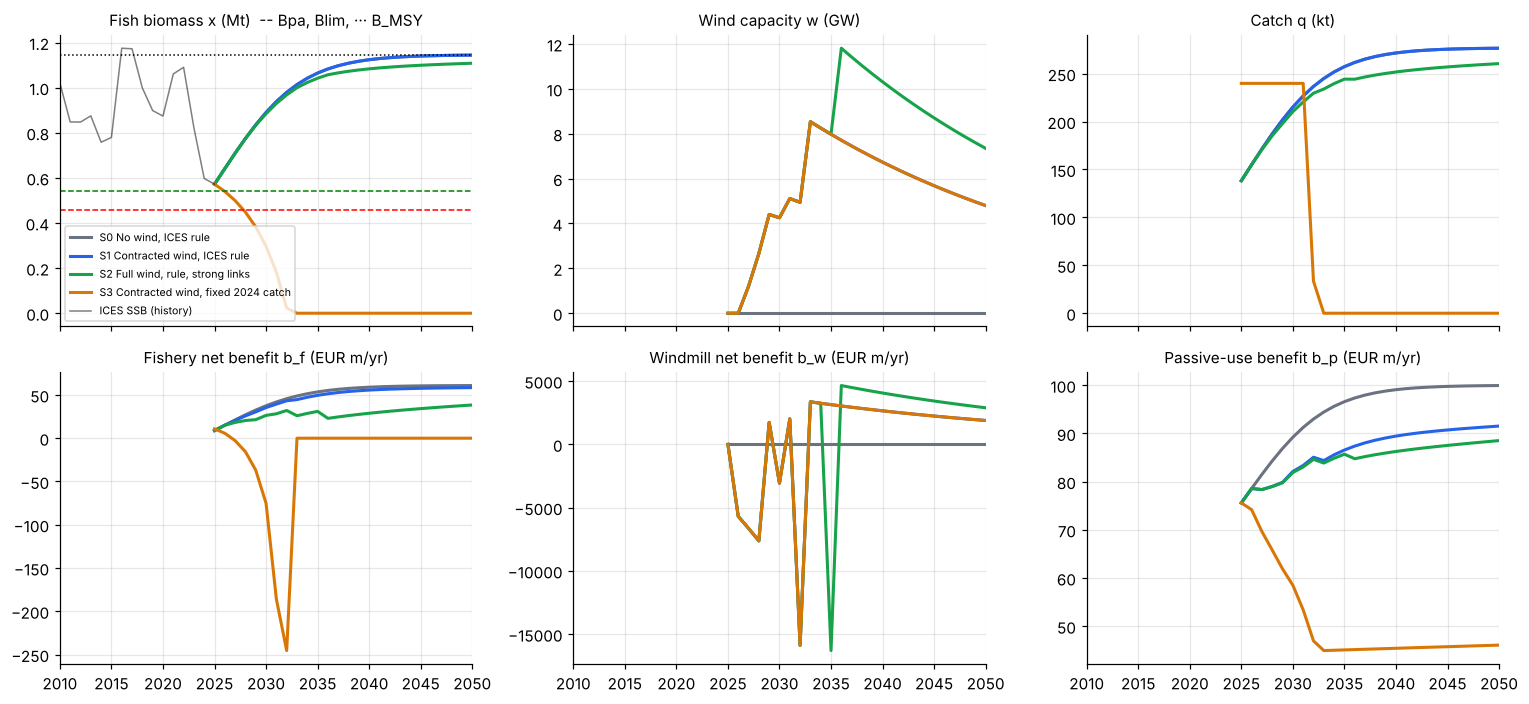

S0 and S1 nearly overlap in the stock panels: with base interactions wind barely touches the stock.


In [ ]:
# Compare state variables (x, w, q) and annual benefits (b_f, b_w, b_p).
fig, ax = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True)
for k, d in runs.items():
    kw = dict(c=COL[k], lw=2, label=f"{k} {SCEN[k][0]}")
    ax[0, 0].plot(d.year, d.x, **kw); ax[0, 1].plot(d.year, d.w, **kw); ax[0, 2].plot(d.year, d.q * 1000, **kw)
    ax[1, 0].plot(d.year, d.bf, **kw); ax[1, 1].plot(d.year, d.bw, **kw); ax[1, 2].plot(d.year, d.bp, **kw)
ax[0, 0].axhline(ref["Bpa"] / 1e6, ls="--", c="g", lw=1); ax[0, 0].axhline(ref["Blim"] / 1e6, ls="--", c="r", lw=1)
ax[0, 0].axhline(Bmsy, ls=":", c="k", lw=1)
ax[0, 0].plot(ices.Year[ices.Year >= 2010], ices.x[ices.Year >= 2010], c="k", lw=1, alpha=.5, label="ICES SSB (history)")
for a in ax.flat: a.set_xlim(2010, 2050)
for a, t in zip(ax.flat, ["Fish biomass x (Mt)  -- Bpa, Blim, ··· B_MSY", "Wind capacity w (GW)", "Catch q (kt)",
                          "Fishery net benefit b_f (EUR m/yr)", "Windmill net benefit b_w (EUR m/yr)", "Passive-use benefit b_p (EUR m/yr)"]):
    a.set_title(t, fontsize=10)
ax[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()
print("S0 and S1 nearly overlap in the stock panels: with base interactions wind barely touches the stock.")

> **Read the plots.** Under the ICES-style rule (S0–S2) catches start lower (the stock is near MSY B<sub>trigger</sub>) and the stock rebuilds towards *B*<sub>MSY</sub>. With the catch fixed at the 2024 level (S3) the fitted stock cannot sustain it and collapses within a decade — the fitted model is pessimistic, but the direction matches ICES advice to cut catches. Windmill benefits are negative in the big investment years and positive once the farms run. Compare S0 and S1 for the cost wind imposes on the fishery, and S1 and S2 for how much that depends on the (assumed) interaction strength.

### Present values by sector

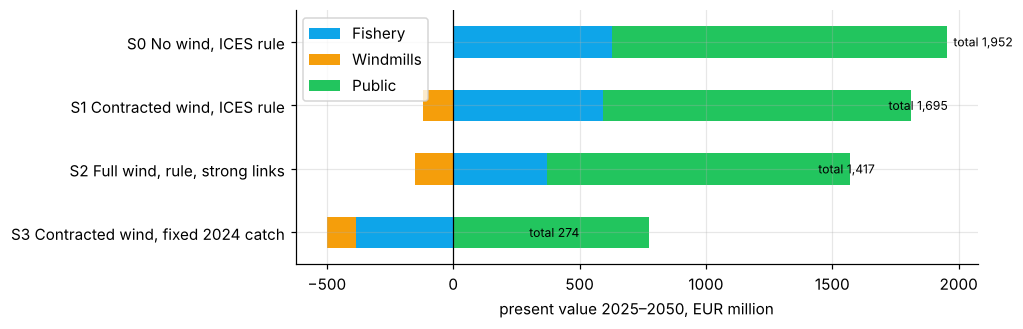

In [ ]:
# Stack sector present values to compare scenario totals.
ax = PV[["Fishery", "Windmills", "Public"]].plot.barh(stacked=True, figsize=(8, 3), color=["#0ea5e9", "#f59e0b", "#22c55e"])
for i, v in enumerate(PV.Total):
    ax.text(v, i, f"  total {v:,.0f}", va="center", fontsize=8)
ax.axvline(0, c="k", lw=.8); ax.set_xlabel("present value 2025–2050, EUR million"); ax.invert_yaxis(); plt.show()

### Fisheries Kobe diagram
Left: model paths, biomass relative to *B*<sub>MSY</sub> and harvest rate relative to *h*<sub>MSY</sub> (green = sustainable). Right: the ICES history of the real stock, SSB / MSY B<sub>trigger</sub> against F / F<sub>MSY</sub>.

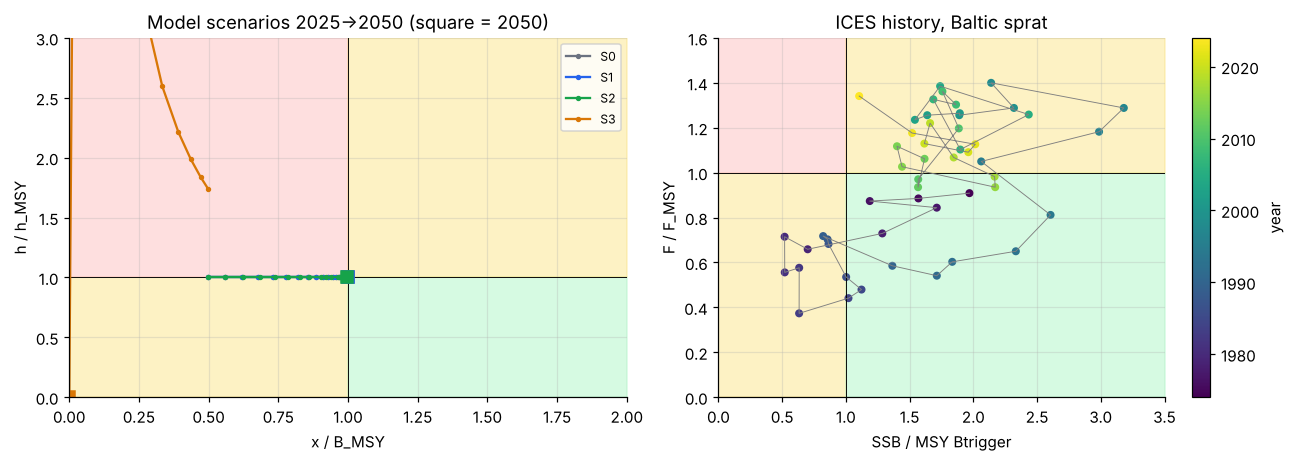

In [ ]:
def kobe_bg(a, xmax, ymax):
    a.fill_between([0, 1], 0, 1, color="#fde68a", alpha=.5); a.fill_between([1, xmax], 0, 1, color="#bbf7d0", alpha=.6)
    a.fill_between([0, 1], 1, ymax, color="#fecaca", alpha=.6); a.fill_between([1, xmax], 1, ymax, color="#fde68a", alpha=.5)
    a.set_xlim(0, xmax); a.set_ylim(0, ymax); a.axhline(1, c="k", lw=.6); a.axvline(1, c="k", lw=.6)

# Normalize biomass and harvest pressure by MSY reference points (Kobe diagram).
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
kobe_bg(ax[0], 2, 3)
for k, d in runs.items():
    Pk = SCEN[k][1]
    bmsy = (Pk["alpha"] - Pk["eps1"] * d.w) / (2 * Pk["beta"]); hmsy = (Pk["alpha"] - Pk["eps1"] * d.w) / 2
    bx, hy = d.x / bmsy, (d.q / d.x.clip(lower=1e-9)) / hmsy
    ax[0].plot(bx, hy, "-o", ms=2.5, c=COL[k], label=k); ax[0].plot(bx.iloc[-1], hy.iloc[-1], "s", ms=8, c=COL[k])
ax[0].set_xlabel("x / B_MSY"); ax[0].set_ylabel("h / h_MSY"); ax[0].set_title("Model scenarios 2025→2050 (square = 2050)"); ax[0].legend(fontsize=8)

kobe_bg(ax[1], 3.5, 1.6)
hist = ices.dropna(subset=["F"])
sc = ax[1].scatter(hist.SSB / ref["MSYBtrigger"], hist.F / ref["FMSY"], c=hist.Year, cmap="viridis", s=18)
ax[1].plot(hist.SSB / ref["MSYBtrigger"], hist.F / ref["FMSY"], c="grey", lw=.6)
plt.colorbar(sc, ax=ax[1], label="year"); ax[1].set_xlabel("SSB / MSY Btrigger"); ax[1].set_ylabel("F / F_MSY")
ax[1].set_title("ICES history, Baltic sprat"); plt.tight_layout(); plt.show()

### Initial and final benefits (radar)
2025 (dashed) against 2050 (solid). Each axis is scaled to the largest value across all scenarios and both dates; negative benefits show as zero. Left: S0 without wind; right: the scenario chosen with `RADAR`.

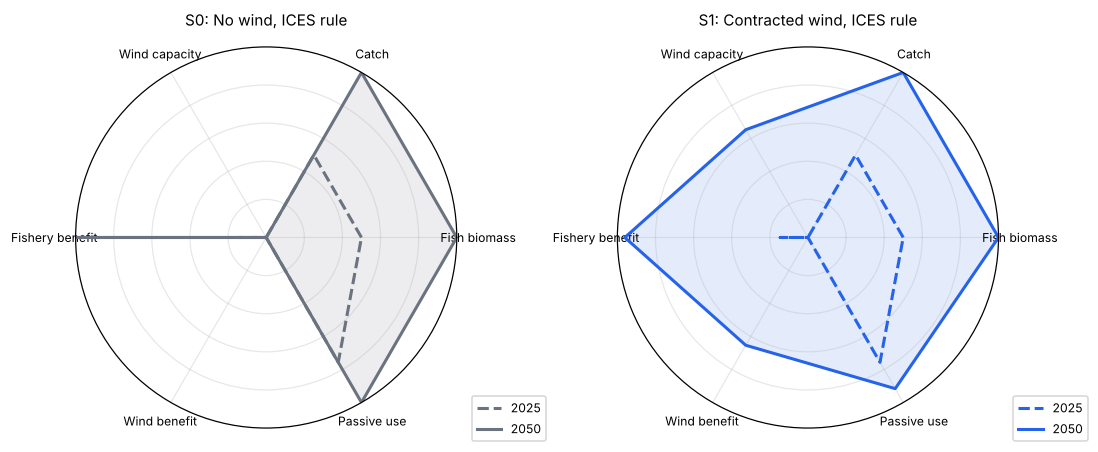

In [ ]:
RADAR = "S1"
axes = ["x", "q", "w", "bf", "bw", "bp"]
labels = ["Fish biomass", "Catch", "Wind capacity", "Fishery benefit", "Wind benefit", "Passive use"]
# Use a shared scale across scenarios and years; negative benefits are clipped for display only.
allv = pd.concat([d[axes].iloc[[0, -1]] for d in runs.values()])
scale = allv.abs().max().replace(0, 1)
ang = np.linspace(0, 2 * np.pi, len(axes), endpoint=False).tolist(); ang += ang[:1]

fig = plt.figure(figsize=(10, 4.2))
for i, k in enumerate(["S0", RADAR]):
    a = fig.add_subplot(1, 2, i + 1, polar=True)
    for row, lab, st in [(0, "2025", "--"), (-1, "2050", "-")]:
        v = (runs[k][axes].iloc[row].clip(lower=0) / scale).tolist(); v += v[:1]
        a.plot(ang, v, st, c=COL[k], lw=2, label=lab); a.fill(ang, v, c=COL[k], alpha=.12 if row else 0)
    a.set_xticks(ang[:-1]); a.set_xticklabels(labels, fontsize=8); a.set_yticklabels([]); a.set_ylim(0, 1)
    a.set_title(f"{k}: {SCEN[k][0]}", fontsize=10, pad=14); a.legend(fontsize=8, loc="lower right", bbox_to_anchor=(1.25, -.05))
plt.tight_layout(); plt.show()

### Equilibrium and individual industries
As on the *Individual industries* sheet: what each sector earns in a sustained steady state, holding the other sector fixed.

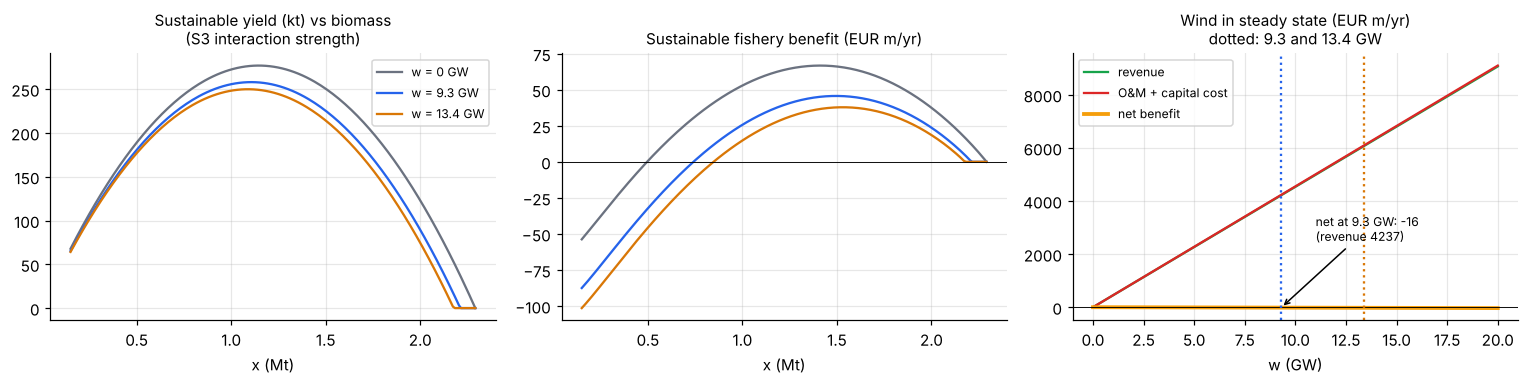

In [ ]:
# Hold wind capacity fixed to show sustainable yield and sector returns over stock levels.
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
xs = np.linspace(0.15, K, 200)
for wv, c in [(0, "#6b7280"), (9.3, "#2563eb"), (13.4, "#d97706")]:
    Pw = S3_P                                                     # strong-interaction case, to make the effect visible
    qs = np.clip((Pw["alpha"] - Pw["eps1"] * wv) * xs - Pw["beta"] * xs**2, 0, None)   # sustainable yield
    bf = Pw["p"] * qs - (Pw["cof1"] + Pw["eps2"] * wv) * qs**Pw["cof2"] / xs
    ax[0].plot(xs, qs * 1000, c=c, label=f"w = {wv} GW"); ax[1].plot(xs, bf, c=c, label=f"w = {wv} GW")
ax[0].set_title("Sustainable yield (kt) vs biomass\n(S3 interaction strength)", fontsize=10); ax[0].set_xlabel("x (Mt)"); ax[0].legend(fontsize=8)
ax[1].set_title("Sustainable fishery benefit (EUR m/yr)", fontsize=10); ax[1].set_xlabel("x (Mt)"); ax[1].axhline(0, c="k", lw=.6)
ws = np.linspace(0, 20, 200)
rev  = P["pe"] * ws
cost = P["cofe1"] * ws**P["cofe2"] + (P["dl"] + P["roi"]) * P["Iwp"] * ws    # O&M + replacement + cost of capital
ax[2].plot(ws, rev, c="#16a34a", label="revenue"); ax[2].plot(ws, cost, c="#dc2626", label="O&M + capital cost")
ax[2].plot(ws, rev - cost, c="#f59e0b", lw=2.5, label="net benefit")
ax[2].axhline(0, c="k", lw=.6); ax[2].axvline(9.3, ls=":", c="#2563eb"); ax[2].axvline(13.4, ls=":", c="#d97706")
i93 = np.abs(ws - 9.3).argmin()
ax[2].annotate(f"net at 9.3 GW: {(rev-cost)[i93]:.0f}\n(revenue {rev[i93]:.0f})", (9.3, (rev-cost)[i93]), xytext=(11, 2500), fontsize=8, arrowprops=dict(arrowstyle="->"))
ax[2].set_title("Wind in steady state (EUR m/yr)\ndotted: 9.3 and 13.4 GW", fontsize=10); ax[2].set_xlabel("w (GW)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Your turn (10 min)

Pick one or two and change the marked lines in the cell below. Re-run it and compare with the table in part 4.

1. **Interactions matter?** Set `eps2` to 10 % of `cof1` per GW and `eps1` so that 13.4 GW cuts growth by 10 %. Does wind change the fishery PV much compared with the catch rule?
2. **The public dislikes turbines.** Use the Excel value `pu3 = -1.1`. Does any wind scenario still beat S0 in total?
3. **Productivity regime.** Back in 3a, set `FIT_FROM = 2000` and re-run parts 3–4. How do *K*, *B*<sub>MSY</sub> and the fixed-catch scenarios change?
4. **Discounting.** Compare `roi = 0.02` and `0.08`. Which sector is most sensitive, and why?
5. **The 26-year horizon cuts off wind revenue.** Turbines built in 2032 are paid for but run only 18 years inside the window. Set `TERMINAL_VALUE = False` (the Excel convention) and see what happens to the wind PV. Also try the Excel O&M exponent `cofe2 = 1.5`.
6. **Policy search.** Which constant harvest rate *h* (catch = *h·x*) maximises total PV with the contracted wind pipeline? (grid search at the bottom)

In [ ]:
# Change the marked assumptions/rules, rerun, and compare with reference scenario S1.
# ---- edit me -------------------------------------------------------------
P_try = {**P,
         "eps1": 0.0,          # exercise 1
         "eps2": 0.01 * P["cof1"],
         "pu3": -0.05,         # exercise 2: try -1.1
         "roi": 0.05,          # exercise 4
         "cofe2": 1.0}         # exercise 5: Excel used 1.5
TERMINAL_VALUE = True          # exercise 5: False = Excel convention
harvest, invest = ices_rule, Iw_contracted
# ---------------------------------------------------------------------------

d = simulate(P_try, harvest, invest, start_year=2025)
pv = present_values(d, P_try, terminal=TERMINAL_VALUE)
print(pd.DataFrame({"your run": pv.values, "S1 reference": PV.iloc[1].values},
                   index=["Fishery", "Windmills", "Public", "Total"]).round(0))

           your run  S1 reference
Fishery       594.0         594.0
Windmills    -118.0        -118.0
Public       1219.0        1219.0
Total        1695.0        1695.0


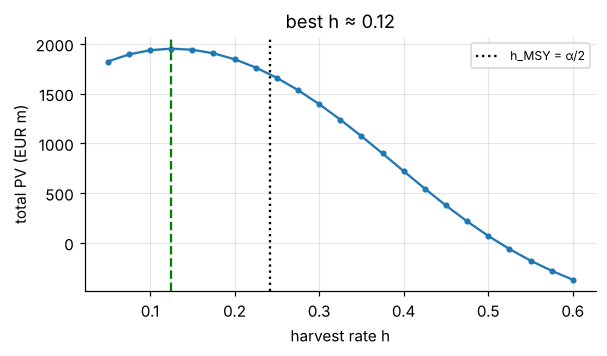

In [ ]:
# Search constant harvest rates h; each candidate applies annual attempted catch q = h*x.
# exercise 6: policy search over a constant harvest rate h
hs = np.linspace(0.05, 0.6, 23)
# Score each candidate by discounted total benefits, including terminal wind value.
tot = [present_values(simulate(P, (lambda h: lambda t, x, w, P: h * x)(h), Iw_contracted, start_year=2025), P, terminal=True).B for h in hs]
best = hs[int(np.argmax(tot))]
plt.figure(figsize=(6, 3)); plt.plot(hs, tot, "-o", ms=3); plt.axvline(best, ls="--", c="g")
plt.axvline(P["alpha"] / 2, ls=":", c="k", label="h_MSY = α/2"); plt.legend(fontsize=8)
plt.xlabel("harvest rate h"); plt.ylabel("total PV (EUR m)"); plt.title(f"best h ≈ {best:.2f}"); plt.show()

## Wrap-up: what was real and what was assumed

| Element | Status | Source / how to improve |
|---|---|---|
| Sprat SSB, catches, F, reference points | **DATA** | ICES SAG API, `spr.27.22-32`, 2025 assessment |
| Growth α, β | **FIT** | Surplus production regression; better: a model with recruitment and temperature |
| Wind capacity and timing | **DATA** | National reporting (Aug 2026), EMODnet `windfarms` — the two disagree on status and years |
| Sprat price | **DATA** | EUMOFA first-sale price, Poland 2024 |
| Wind price, investment cost | **DATA** | Dec 2025 auction (~€115/MWh); Baltica 2 investment |
| Fishing costs | **ASSUMPTION** | STECF Annual Economic Report, Polish pelagic trawl segment |
| Capacity factor (0.45), O&M (€60 m/GW·yr), lifetime | **ASSUMPTION** | Project disclosures, operator data |
| ε₁, ε₂ (wind ↔ fishery) | **ASSUMPTION** | Overlay of farm polygons with ICES VMS fishing effort; reef-effect studies |
| Passive use *u*₁…*u*₃ | **ASSUMPTION** | Benefit transfer from Baltic valuation studies (e.g. BalticSTERN) |

**Simplifications to keep in mind:** one Baltic-wide sprat stock is set against Polish wind only; the model's *x* is SSB, not total biomass; investment is booked in the completion year; wind capacity depreciates exponentially (Excel's δ) rather than retiring at end of life; the terminal value is a rough replacement-cost estimate. Wind is valued only at its market (auction) revenue — no climate or energy-security value is counted, which would favour wind.

**Spatial extension:** `baltic_ses_spatial_extension.ipynb` replaces the assumed capacity factor and passive-use term with site data (ERA5 wind, Natura 2000, OBIS) and compares siting portfolios.

**Next step** (the follow-up project): replace the ASSUMPTION rows with data through the Seadots connectors and building blocks, and scale the stock to the selected area with VMS effort.

### Sources
* ICES Stock Assessment Graphs, spr.27.22-32 (assessment key 20915): https://sag.ices.dk/SAG_API/api/SummaryTable?assessmentKey=20915 — advice https://doi.org/10.17895/ices.advice.27202893
* EMODnet Human Activities, wind farms WFS: https://ows.emodnet-humanactivities.eu/wfs (`emodnet:windfarms`)
* Polish offshore wind status, gramwzielone.pl (26 Aug 2026): https://www.gramwzielone.pl/?p=20373718
* Polish offshore wind auction results, WindEurope (19 Dec 2025): https://windeurope.org/news/poland-powers-ahead-first-offshore-wind-auction-delivers-strong-results/
* Baltica 2 investment, Notes from Poland (31 Jan 2025): https://notesfrompoland.com/2025/01/31/pge-and-orsted-set-to-build-polands-second-offshore-wind-farm-for-e7-11-billion/
* EUMOFA, European sprat species profile: https://fishery-aquaculture-market-observatory.ec.europa.eu/en/country-and-species-profiles/species-profiles/european-sprat
* Model: *Case-example II.xlsx* (R. Arnason), SES modelling training, SEAtwins Symposium, 4 Nov 2026